In [1]:
# Student Name: Mohammad Abdalrouf Alnaghmoush
# Student ID: 2230004028


# Transformers


#### A Transformer is a deep learning architecture designed to process sequences of text using self-attention.

- Transformers are the foundation of many modern NLP models, including BERT, GPT, and T5.

- Before Transformers, we used models such as RNNs and LSTMs for NLP tasks.

<img src="https://drive.google.com/thumbnail?id=1unPqGaKftHxp37-F99Bg6hJzFbQdCGC7&sz=w1000" width="700">

In [2]:
%pip -q install transformers torch matplotlib


[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 1. Load a Transformer

We use **DistilBERT**, a  Transformer fine-tuned for positive/negative sentiment classification.

In [3]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification
import torch
torch.manual_seed(42)
torch.set_num_threads(2)
model_name = "distilbert-base-uncased-finetuned-sst-2-english"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModelForSequenceClassification.from_pretrained(model_name, attn_implementation="eager")
model.eval()
print("Pretrained model:", model_name)
print("Transformer layers:", model.config.n_layers)
print("Attention heads per layer:", model.config.n_heads)
print("Hidden size:", model.config.dim)

/opt/hostedtoolcache/Python/3.11.18/x64/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Pretrained model: distilbert-base-uncased-finetuned-sst-2-english
Transformer layers: 6
Attention heads per layer: 12
Hidden size: 768



<img src="https://drive.google.com/thumbnail?id=1v2dRK1KR_ydZOknjj8Xv8_wjOdXleDYs&sz=w1000" width="500">

## 2. Tokenizing the text

In [4]:
sentence = "The movie was not good."

# Tokenization: converts text into token IDs
inputs = tokenizer(sentence, return_tensors="pt")

# [CLS] = start token, [SEP] = end token
tokens = tokenizer.convert_ids_to_tokens(inputs["input_ids"][0])

print("Tokens:", tokens)

Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']


## 3. Embeddings and self-attention

Each token ID becomes a **vector (embedding)**. Inside each Transformer layer, **self-attention** lets a token use information from other tokens in the same sentence.

In [5]:
import torch

# Enable attention weights
# Eager attention enabled in the model-loading cell

with torch.no_grad():
    embeddings = model.distilbert.embeddings(inputs["input_ids"])
    outputs = model(**inputs, output_attentions=True)

# Attention from the first layer and first head
attention = outputs.attentions[0][0, 0]

print("Embeddings shape:", embeddings.shape)
print("Attention shape:", attention.shape)
print("Tokens:", tokens)
print("Attention weights:\n", attention)

Embeddings shape: torch.Size([1, 8, 768])
Attention shape: torch.Size([8, 8])
Tokens: ['[CLS]', 'the', 'movie', 'was', 'not', 'good', '.', '[SEP]']
Attention weights:
 tensor([[0.1145, 0.0938, 0.0681, 0.0701, 0.0596, 0.0800, 0.1593, 0.3546],
        [0.4147, 0.0793, 0.0481, 0.1018, 0.1084, 0.0805, 0.0789, 0.0883],
        [0.1634, 0.0327, 0.0975, 0.0403, 0.1819, 0.1402, 0.0866, 0.2574],
        [0.2882, 0.1014, 0.0504, 0.0669, 0.2180, 0.1009, 0.1231, 0.0511],
        [0.3612, 0.0501, 0.0696, 0.1200, 0.0642, 0.1304, 0.0953, 0.1092],
        [0.3065, 0.0469, 0.1175, 0.1915, 0.0630, 0.0555, 0.1120, 0.1071],
        [0.3505, 0.0935, 0.0572, 0.0753, 0.0972, 0.0964, 0.1165, 0.1135],
        [0.3513, 0.1019, 0.0318, 0.0541, 0.1036, 0.0607, 0.0755, 0.2210]])


## 4. Classification: From Transformer to prediction

The Transformer produces contextual representations. The **classification head** turns them into two scores (*logits*). **Softmax** converts these into probabilities that sum to 1.

In [6]:
# Get prediction scores from the Transformer
with torch.no_grad():
    logits = model(**inputs).logits

# Convert scores into probabilities
probs = torch.softmax(logits, dim=1)[0]

# Display the prediction
prediction = probs.argmax().item()

print("Prediction:", model.config.id2label[prediction])
print("Confidence:", round(probs[prediction].item(), 3))


Prediction: NEGATIVE
Confidence: 1.0



### Task: Exploring Transformer Layers and Attention Heads

Load the pretrained **`bert-base-uncased`** model using Hugging Face Transformers.

1. Write code to print the number of Transformer layers and the number of attention heads per layer.
2. Calculate and print the total number of attention heads across all Transformer layers.
3. Using the sentence `"Transformers use self-attention to understand language."`, extract the attention weights from the **third Transformer layer and second attention head**.
4. Explain what the rows and columns of the attention matrix represent.

## Complete solution — Exploring Transformer Layers and Attention Heads
The following tasks use the actual **pretrained `bert-base-uncased` model** and the exact sentence specified in the question. The tokenizer and model weights are downloaded automatically on first execution; no external CSV dataset is required by this lab.


In [7]:
from transformers import AutoModel, AutoTokenizer
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Tasks 1 and 2 — count layers and attention heads for pretrained BERT.
bert_name = "bert-base-uncased"
bert_tokenizer = AutoTokenizer.from_pretrained(bert_name)
bert_model = AutoModel.from_pretrained(bert_name, attn_implementation="eager")
bert_model.eval()

layers = int(bert_model.config.num_hidden_layers)
heads_per_layer = int(bert_model.config.num_attention_heads)
total_heads = layers * heads_per_layer
print("Model:", bert_name)
print("Transformer layers:", layers)
print("Attention heads per layer:", heads_per_layer)
print("Total attention heads:", total_heads)
assert (layers, heads_per_layer, total_heads) == (12, 12, 144)


Model: bert-base-uncased
Transformer layers: 12
Attention heads per layer: 12
Total attention heads: 144


In [8]:
# Task 3 — actual attention weights from the THIRD layer and SECOND head.
sentence_bert = "Transformers use self-attention to understand language."
tokenized_bert = bert_tokenizer(sentence_bert, return_tensors="pt")
tokens_bert = bert_tokenizer.convert_ids_to_tokens(tokenized_bert["input_ids"][0])

with torch.inference_mode():
    attention_outputs = bert_model(**tokenized_bert, output_attentions=True)

assert len(attention_outputs.attentions) == layers
# Zero-based indexes: [2] third layer; [0, 1] first item and second head.
head_attention = attention_outputs.attentions[2][0, 1].cpu().numpy()
assert head_attention.shape == (len(tokens_bert), len(tokens_bert))
assert np.allclose(head_attention.sum(axis=1), 1.0, atol=1e-5)

print("Sentence:", sentence_bert)
print("Tokens:", tokens_bert)
print("Layer 3 — Head 2 matrix dimensions:", head_attention.shape)
print("All row sums are approximately 1:", np.allclose(head_attention.sum(axis=1), 1.0, atol=1e-5))
matrix_table = pd.DataFrame(head_attention, index=tokens_bert, columns=tokens_bert)
matrix_table.index.name = "Query token (row)"
matrix_table.columns.name = "Key token (column)"
display(matrix_table.round(4))


Sentence: Transformers use self-attention to understand language.
Tokens: ['[CLS]', 'transformers', 'use', 'self', '-', 'attention', 'to', 'understand', 'language', '.', '[SEP]']
Layer 3 — Head 2 matrix dimensions: (11, 11)
All row sums are approximately 1: True


Key token (column),[CLS],transformers,use,self,-,attention,to,understand,language,.,[SEP]
Query token (row),,,,,,,,,,,
[CLS],0.7318,0.0079,0.0106,0.0056,0.0165,0.0069,0.0101,0.0116,0.0055,0.0386,0.1550
transformers,0.8888,0.0047,0.0344,0.0002,0.0027,0.0051,0.0009,0.0007,0.0004,0.0051,0.0570
use,0.1427,0.5689,0.0054,0.0353,0.0412,0.0679,0.0896,0.0003,0.0053,0.0090,0.0343
self,0.3395,0.0732,0.0015,0.0002,0.2016,0.0811,0.0636,0.0257,0.0016,0.0285,0.1835
-,0.1429,0.0697,0.0713,0.6394,0.0121,0.0128,0.0034,0.0026,0.0142,0.0093,0.0223
attention,0.1126,0.5448,0.0116,0.0203,0.1112,0.0102,0.0724,0.0001,0.0001,0.0164,0.1003
to,0.0841,0.0224,0.6222,0.0085,0.0091,0.1936,0.0110,0.0072,0.0008,0.0140,0.0271
understand,0.4336,0.0050,0.0023,0.0216,0.0119,0.0030,0.3296,0.0024,0.0554,0.0533,0.0820
language,0.0513,0.0005,0.4292,0.0016,0.0045,0.0013,0.0051,0.3980,0.0059,0.0407,0.0620


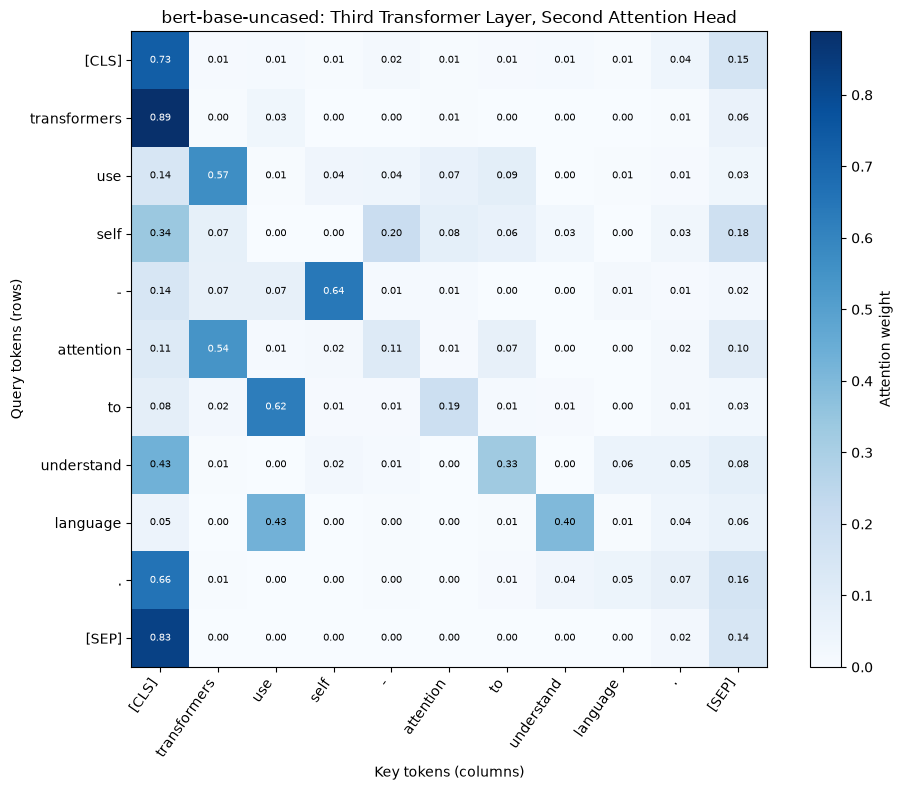

In [9]:
# Actual attention heatmap — saved as a visible image in the notebook outputs.
# Force Jupyter's inline backend so GitHub renders the saved image output.
get_ipython().run_line_magic("matplotlib", "inline")
fig, ax = plt.subplots(figsize=(10, 8))
max_weight = float(head_attention.max())
heat = ax.imshow(head_attention, cmap="Blues", vmin=0, vmax=max_weight)
ax.set_xticks(range(len(tokens_bert)), labels=tokens_bert, rotation=55, ha="right")
ax.set_yticks(range(len(tokens_bert)), labels=tokens_bert)
ax.set_xlabel("Key tokens (columns)")
ax.set_ylabel("Query tokens (rows)")
ax.set_title("bert-base-uncased: Third Transformer Layer, Second Attention Head")
fig.colorbar(heat, ax=ax, label="Attention weight")
for row in range(len(tokens_bert)):
    for col in range(len(tokens_bert)):
        value = float(head_attention[row, col])
        ax.text(col, row, f"{value:.2f}", ha="center", va="center", fontsize=7,
                color="white" if value > max_weight * 0.55 else "black")
fig.tight_layout()
plt.show()


### Task 4 — What do the rows and columns of the attention matrix represent?

- **Rows = query tokens:** Each row represents a token whose attention distribution is being computed.
- **Columns = key tokens:** Each column represents a token that the query token can attend to.
- **Cell `[i,j]`:** The weight of the token in row `i` attending to the token in column `j`, in this particular head.
- **Normalization:** Each row's weights are nonnegative and sum to approximately 1 because a softmax normalizes across all key-token positions.
- **Special tokens:** BERT uses WordPiece tokenization; punctuation, hyphens, `[CLS]`, and `[SEP]` may appear as separate entries.

The matrix captures one head in the third layer, **not the whole model**. Attention weights should not be interpreted as a causal explanation for the classification result.


In [10]:
# Task 4 — Inspect the relationship between query rows and key columns.
row_sums = head_attention.sum(axis=1)
print("Every row sums to 1:", bool(np.allclose(row_sums, 1, atol=1e-5)))
print("Top attended-to token (column) for each query token (row):")
for query, distribution in zip(tokens_bert, head_attention):
    best = int(distribution.argmax())
    print(f"{query:>15s} -> {tokens_bert[best]:<15s} | weight={distribution[best]:.4f}")


Every row sums to 1: True
Top attended-to token (column) for each query token (row):
          [CLS] -> [CLS]           | weight=0.7318
   transformers -> [CLS]           | weight=0.8888
            use -> transformers    | weight=0.5689
           self -> [CLS]           | weight=0.3395
              - -> self            | weight=0.6394
      attention -> transformers    | weight=0.5448
             to -> use             | weight=0.6222
     understand -> [CLS]           | weight=0.4336
       language -> use             | weight=0.4292
              . -> [CLS]           | weight=0.6580
          [SEP] -> [CLS]           | weight=0.8278
